In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import folium
from folium.plugins import HeatMap

df = pd.read_csv('/content/crime_dataset_india.csv')
df.shape, df.isna().sum()

((40160, 14),
 Report Number             0
 Date Reported             0
 Date of Occurrence        0
 Time of Occurrence        0
 City                      0
 Crime Code                0
 Crime Description         0
 Victim Age                0
 Victim Gender             0
 Weapon Used            5790
 Crime Domain              0
 Police Deployed           0
 Case Closed               0
 Date Case Closed      20098
 dtype: int64)

In [2]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df['city'] = df['city'].str.strip().str.title()
df['crime_description'] = df['crime_description'].str.strip().str.title()
df = df.drop_duplicates()

df['date'] = pd.to_datetime(df['date_of_occurrence'], format='%m-%d-%Y %H:%M')
df['hour'] = pd.to_datetime(df['time_of_occurrence'], format='%d-%m-%Y %H:%M').dt.hour
df['year'] = df.date.dt.year
df['month'] = df.date.dt.month_name()
df['day'] = df.date.dt.day_name()
df['day_type'] = np.where(df.date.dt.dayofweek >= 5, 'Weekend', 'Weekday')

def period(h):
    if 5 <= h < 11: return 'Morning'
    if 11 <= h < 16: return 'Afternoon'
    if 16 <= h < 20: return 'Evening'
    return 'Night'
df['time_period'] = df['hour'].apply(period)

In [3]:
women_crimes = ['Sexual Assault','Domestic Violence','Kidnapping','Assault','Cybercrime','Extortion']
w = df[(df.victim_gender == 'F') & df.crime_description.isin(women_crimes)].copy()
len(w)   # 6384

6384

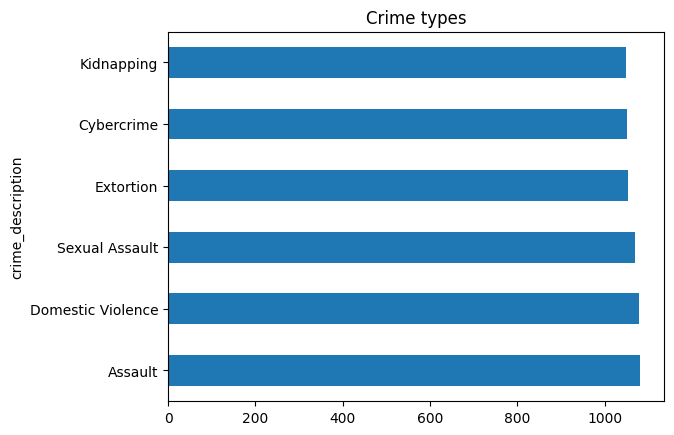

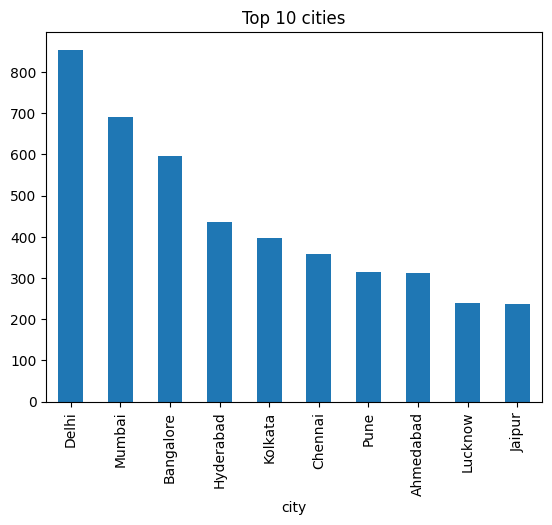

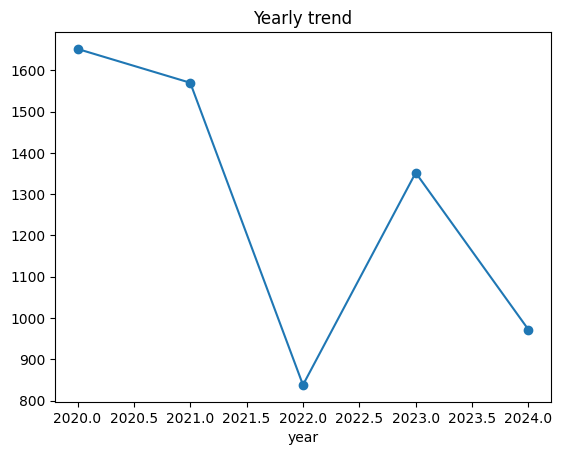

,count
day_type,
Weekday,4524
Weekend,1860


In [4]:
w.crime_description.value_counts().plot(kind='barh', title='Crime types')
plt.show()
w.city.value_counts().head(10).plot(kind='bar', title='Top 10 cities')
plt.show()
w.groupby('year').size().plot(marker='o', title='Yearly trend')   # 2024 is partial (to July)
plt.show()
w.day_type.value_counts()

In [5]:
city = w.groupby('city').size().rename('incidents').reset_index()
city['score'] = city.incidents / city.incidents.max() * 100
city['level'] = pd.cut(city.score, [-1,30,60,80,100],
                       labels=['Low','Medium','High','Very High'])
city.sort_values('score', ascending=False)

,city,incidents,score,level
5,Delhi,854,100.000000,Very High
17,Mumbai,690,80.796253,Very High
2,Bangalore,595,69.672131,High
8,Hyderabad,435,50.936768,Medium
13,Kolkata,397,46.487119,Medium
4,Chennai,358,41.920375,Medium
21,Pune,314,36.768150,Medium
1,Ahmedabad,312,36.533958,Medium
14,Lucknow,240,28.103044,Low
10,Jaipur,237,27.751756,Low


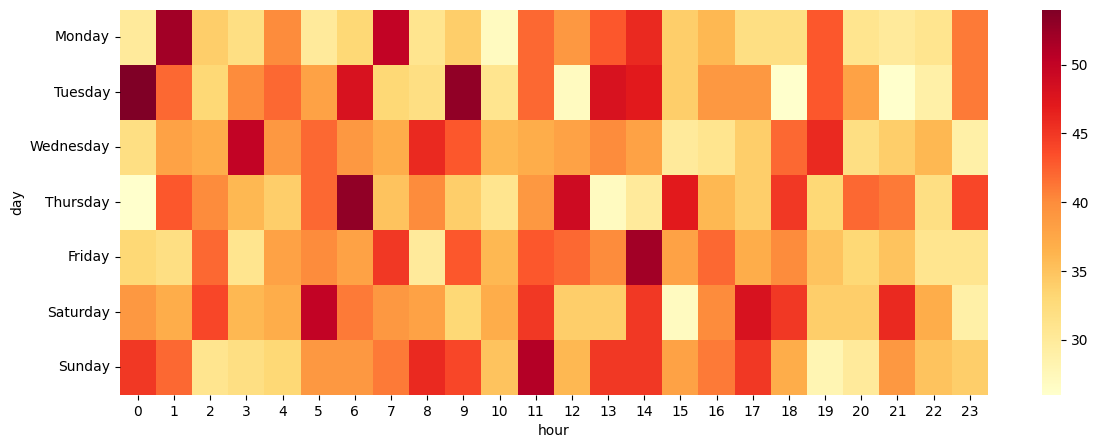

In [6]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pv = w.pivot_table(index='day', columns='hour', values='report_number',
                   aggfunc='count', fill_value=0).reindex(order)
plt.figure(figsize=(14,5))
sns.heatmap(pv, cmap='YlOrRd')
plt.show()

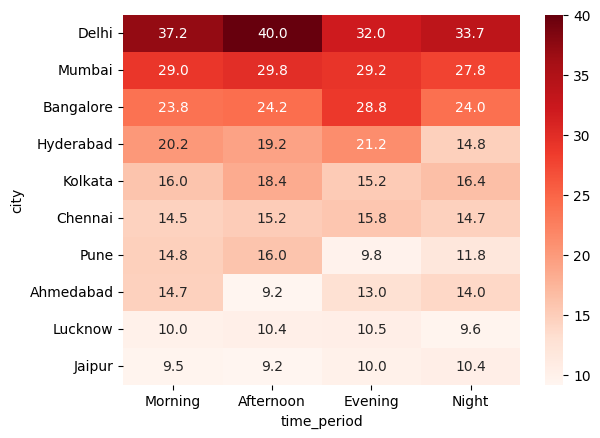

In [7]:
ct = pd.crosstab(w.city, w.time_period)[['Morning','Afternoon','Evening','Night']]
# Night spans 9 hours and evening only 4, so compare incidents per hour
hours = {'Morning':6,'Afternoon':5,'Evening':4,'Night':9}
ct_rate = ct / pd.Series(hours)
sns.heatmap(ct_rate.loc[w.city.value_counts().head(10).index], annot=True, fmt='.1f', cmap='Reds')
plt.show()

In [14]:
m = folium.Map(
    location=[22.5, 79], zoom_start=5,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri'
)

In [16]:
w['lat'] = w.city.map(lambda c: coords[c][0])
w['lon'] = w.city.map(lambda c: coords[c][1])

CELL = 2.0   # grid size in degrees; try 1.0 or 3.0 and compare
w['gx'] = np.floor(w.lon / CELL) * CELL
w['gy'] = np.floor(w.lat / CELL) * CELL

grid = (w.groupby(['gy','gx'])
          .agg(incidents=('report_number','count'),
               cities=('city', lambda s: ', '.join(sorted(s.unique()))))
          .reset_index())
grid['score'] = grid.incidents / grid.incidents.max() * 100
grid['level'] = pd.cut(grid.score, [-1,30,60,80,100],
                       labels=['Low','Medium','High','Very High'])

display(grid.sort_values('score', ascending=False))   # shows the table

# Map
m = folium.Map(
    location=[22.5, 79], zoom_start=5,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri'
)
col = {'Low':'green','Medium':'orange','High':'red','Very High':'darkred'}
for _, r in grid.iterrows():
    folium.Rectangle([[r.gy, r.gx], [r.gy+CELL, r.gx+CELL]],
        color=col[r.level], fill=True, fill_opacity=0.5,
        popup=f"{r.cities}: {r.incidents} ({r.level})").add_to(m)
m

,gy,gx,incidents,cities,score,level
4,18.0,72.0,1300,"Kalyan, Mumbai, Nashik, Pune, Thane, Vasai",100.000000,Very High
17,28.0,76.0,1098,"Delhi, Faridabad, Ghaziabad, Meerut",84.461538,Very High
0,12.0,76.0,595,Bangalore,45.769231,Medium
2,16.0,78.0,435,Hyderabad,33.461538,Medium
16,26.0,80.0,405,"Kanpur, Lucknow",31.153846,Medium
11,22.0,88.0,397,Kolkata,30.538462,Medium
1,12.0,80.0,358,Chennai,27.538462,Low
8,22.0,72.0,312,Ahmedabad,24.000000,Low
14,26.0,74.0,237,Jaipur,18.230769,Low
5,20.0,72.0,208,Surat,16.000000,Low


In [17]:
from sklearn.cluster import DBSCAN
X = np.radians(city[['lat','lon']].values)
city['cluster'] = DBSCAN(eps=100/6371, min_samples=2, metric='haversine').fit_predict(X)
city.groupby('cluster').agg(cities=('city', list), incidents=('incidents','sum'))

,cities,incidents
cluster,,
-1,"[Agra, Ahmedabad, Bangalore, Bhopal, Chennai, ...",3959
0,"[Delhi, Faridabad, Ghaziabad, Meerut]",1098
1,"[Kalyan, Mumbai, Thane, Vasai]",922
2,"[Kanpur, Lucknow]",405


In [18]:
w.groupby('city').agg(incidents=('report_number','count'),
                      avg_police=('police_deployed','mean'),
                      closure_rate=('case_closed', lambda s:(s=='Yes').mean())
                     ).sort_values('incidents', ascending=False).head(10)

,incidents,avg_police,closure_rate
city,,,
Delhi,854,9.940281,0.505855
Mumbai,690,9.840580,0.491304
Bangalore,595,9.926050,0.490756
Hyderabad,435,9.956322,0.560920
Kolkata,397,9.856423,0.526448
Chennai,358,10.608939,0.502793
Pune,314,10.175159,0.500000
Ahmedabad,312,10.086538,0.509615
Lucknow,240,10.329167,0.487500


In [19]:
w.to_csv('women_crimes_clean.csv', index=False)

from google.colab import files
files.download('women_crimes_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>